**Hidden Markov Model**

After observing inflation through month $t$, the HMM calculates the **filtered probability** $P(S_t=s \mid Inflation_1,\ldots,Inflation_t)$. It uses no observations after month $t$. To forecast month $t+1$, the transition matrix converts these filtered probabilities into predicted probabilities $P(S_{t+1}=s \mid Information_t)$.

Given the hidden state, the simple inflation equation is:

$$Inflation_t = \mu_{S_t} + error_t$$

- $\mu_{S_t}$ is the average inflation associated with that state.
- The state can persist or switch according to transition probabilities.

This is the **model equation conditional on the hidden state**. Because $S_t$ is unknown when we forecast, the numerical one-month-ahead forecast combines every state mean using its predicted probability:

$$\widehat{Inflation}_t = \sum_{s=0}^{1} P(S_t=s \mid Information_{t-1})\mu_s$$

In [10]:
# Choose one: 'database' or 'csv'
DATA_SOURCE = 'database'

# Two states keep the first HMM understandable.
N_STATES = 2

# Keep the same test start used by AR(1) and ARX.
TEST_START = '2017-01-01'

In [11]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

search_locations = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(path for path in search_locations if (path / 'README.md').exists())
CSV_PATH = PROJECT_ROOT / 'data' / 'processed' / 'US' / 'us_macro_2007_2023.csv'
print('Selected source:', DATA_SOURCE)

Selected source: database


**Load US CPI**

In [12]:
if DATA_SOURCE == 'database':
    from sqlalchemy import text

    sys.path.insert(0, str(PROJECT_ROOT))
    from modelling.config import get_sqlalchemy_engine

    engine = get_sqlalchemy_engine()
    query = text("""
        SELECT month_date, cpi_value
        FROM analytics.Monthly_Region_Wide_View
        WHERE region_code = 'US'
        ORDER BY month_date
    """)
    raw = pd.read_sql(query, engine, parse_dates=['month_date'])
    raw = raw.rename(columns={'month_date': 'Date', 'cpi_value': 'CPI'})
else:
    raw = pd.read_csv(
        CSV_PATH, usecols=['Date', 'CPIAUCSL'], parse_dates=['Date']
    ).rename(columns={'CPIAUCSL': 'CPI'})

raw = raw.sort_values('Date').drop_duplicates('Date').set_index('Date')
raw['CPI'] = pd.to_numeric(raw['CPI'], errors='coerce')
print('Rows:', len(raw))
print('Period:', raw.index.min().date(), 'to', raw.index.max().date())
raw.head()

Rows: 204
Period: 2007-01-01 to 2023-12-01


,CPI
Date,
2007-01-01,203.437
2007-02-01,204.226
2007-03-01,205.288
2007-04-01,205.904
2007-05-01,206.755


**Calculate year-over-year inflation**

In [13]:
data = raw.copy()
data['Inflation_YoY'] = data['CPI'].pct_change(12, fill_method=None) * 100
inflation = data['Inflation_YoY'].dropna().copy()

print('Usable months:', len(inflation))
print('HMM period:', inflation.index.min().date(), 'to', inflation.index.max().date())
inflation.head()

Usable months: 192
HMM period: 2008-01-01 to 2023-12-01


Date
2008-01-01    4.294696
2008-02-01    4.142959
2008-03-01    3.974904
2008-04-01    3.903761
2008-05-01    4.088414
Name: Inflation_YoY, dtype: float64

**Estimate the two-state HMM**

In [14]:
np.random.seed(42)

hmm_model = sm.tsa.MarkovRegression(
    inflation,
    k_regimes=N_STATES,
    trend='c',
    switching_variance=False,
)
hmm_result = hmm_model.fit(
    disp=False, maxiter=1000, search_reps=10
)

print('Model converged:', hmm_result.mle_retvals.get('converged', False))

c:\Users\zahra\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


Model converged: True


In [15]:
state_means = {
    state: hmm_result.params[f'const[{state}]']
    for state in range(N_STATES)
}
low_state = min(state_means, key=state_means.get)
high_state = max(state_means, key=state_means.get)
state_names = {
    low_state: 'Lower inflation',
    high_state: 'Higher inflation',
}

smoothed_probabilities = hmm_result.smoothed_marginal_probabilities.copy()
most_likely_state = smoothed_probabilities.idxmax(axis=1)

regime_history = pd.DataFrame({
    'Inflation_YoY': inflation,
    'State': most_likely_state,
})
regime_history['Regime'] = regime_history['State'].map(state_names)

regime_summary = pd.DataFrame({
    'Estimated average inflation (%)': [
        state_means[low_state], state_means[high_state]
    ],
    'Months classified in regime': [
        (most_likely_state == low_state).sum(),
        (most_likely_state == high_state).sum(),
    ],
}, index=['Lower inflation', 'Higher inflation'])
regime_summary

,Estimated average inflation (%),Months classified in regime
Lower inflation,1.648888,157
Higher inflation,6.113207,35


**Transition probabilities**

In [ ]:
raw_transition = hmm_result.regime_transition[:, :, 0]
ordered_states = [low_state, high_state]

transition_table = pd.DataFrame(
    [
        [raw_transition[next_state, current_state] for next_state in ordered_states]
        for current_state in ordered_states
    ],
    index=['From lower inflation', 'From higher inflation'],
    columns=['To lower inflation', 'To higher inflation'],
)
transition_table.round(3)

,To lower inflation,To higher inflation
From lower inflation,0.989,0.011
From higher inflation,0.037,0.963


In [17]:
print(
    'Probability of remaining in the lower-inflation regime:',
    f'{transition_table.loc["From lower inflation", "To lower inflation"]:.1%}'
)
print(
    'Probability of remaining in the higher-inflation regime:',
    f'{transition_table.loc["From higher inflation", "To higher inflation"]:.1%}'
)

Probability of remaining in the lower-inflation regime: 98.9%
Probability of remaining in the higher-inflation regime: 96.3%


**Plot the historical regimes**

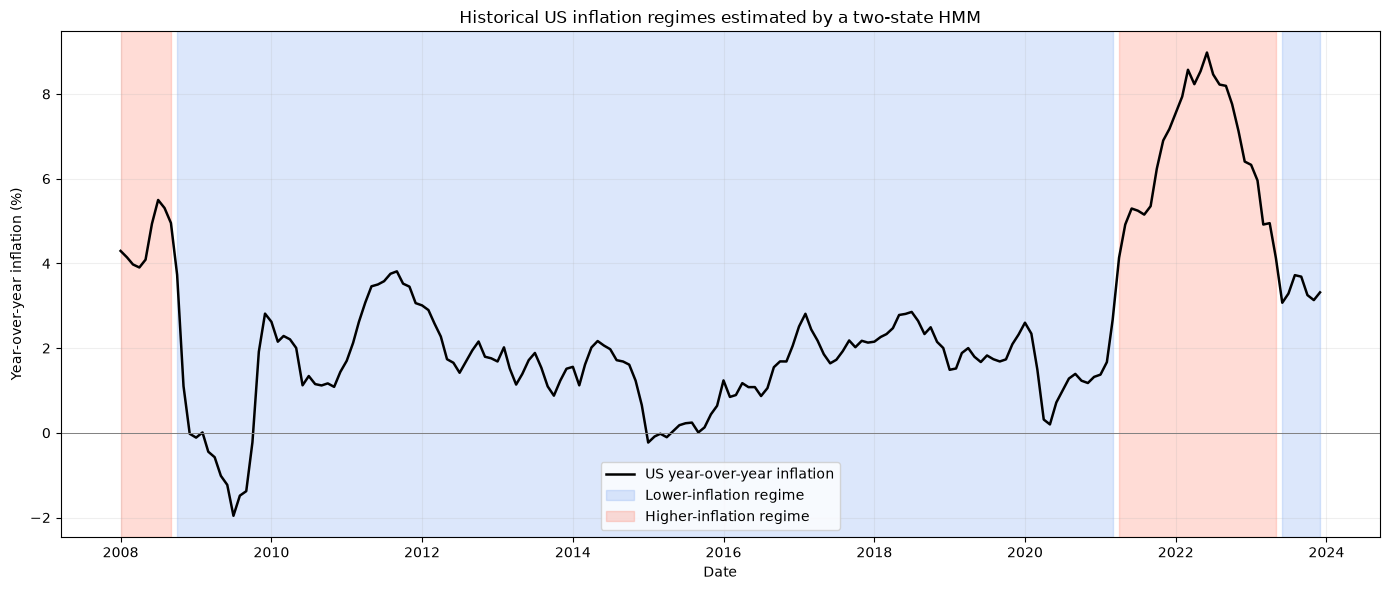

In [18]:
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(
    regime_history.index, regime_history['Inflation_YoY'],
    color='black', linewidth=1.8, label='US year-over-year inflation'
)

plot_min = regime_history['Inflation_YoY'].min() - 0.5
plot_max = regime_history['Inflation_YoY'].max() + 0.5
ax.fill_between(
    regime_history.index, plot_min, plot_max,
    where=(regime_history['State'] == low_state),
    color='cornflowerblue', alpha=0.22, label='Lower-inflation regime'
)
ax.fill_between(
    regime_history.index, plot_min, plot_max,
    where=(regime_history['State'] == high_state),
    color='tomato', alpha=0.22, label='Higher-inflation regime'
)
ax.axhline(0, color='gray', linewidth=0.7)
ax.set_ylim(plot_min, plot_max)
ax.set_title('Historical US inflation regimes estimated by a two-state HMM')
ax.set_ylabel('Year-over-year inflation (%)')
ax.set_xlabel('Date')
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## HMM forecasting

**Split to train/test dataset**

In [19]:
forecast_data = raw.copy()
forecast_data['Inflation_MoM'] = (
    forecast_data['CPI'].pct_change(1, fill_method=None) * 100
)
forecast_data['Inflation_Lag1'] = forecast_data['Inflation_MoM'].shift(1)
forecast_data = forecast_data[[
    'Inflation_MoM', 'Inflation_Lag1'
]].dropna().copy()

test_start = pd.Timestamp(TEST_START)
forecast_train = forecast_data.loc[forecast_data.index < test_start].copy()
forecast_test = forecast_data.loc[forecast_data.index >= test_start].copy()

if forecast_train.empty or forecast_test.empty:
    raise ValueError('TEST_START must leave observations in both periods.')

print('Training period:', forecast_train.index.min().date(), 'to', forecast_train.index.max().date())
print('Training months:', len(forecast_train))
print('Test period:    ', forecast_test.index.min().date(), 'to', forecast_test.index.max().date())
print('Test months:    ', len(forecast_test))

Training period: 2007-03-01 to 2016-12-01
Training months: 118
Test period:     2017-01-01 to 2023-12-01
Test months:     84


**Fit the forecasting HMM only on training data**

In [20]:
np.random.seed(42)

forecast_hmm_model = sm.tsa.MarkovRegression(
    forecast_train['Inflation_MoM'],
    k_regimes=N_STATES,
    trend='c',
    switching_variance=False,
)
forecast_hmm_result = forecast_hmm_model.fit(
    disp=False, maxiter=1000, search_reps=20
)

forecast_state_means = np.array([
    forecast_hmm_result.params[f'const[{state}]']
    for state in range(N_STATES)
])
forecast_variance = max(float(forecast_hmm_result.params['sigma2']), 1e-12)
forecast_transition = forecast_hmm_result.regime_transition[:, :, 0]

pd.DataFrame({
    'Estimated monthly mean (%)': forecast_state_means
}, index=[f'State {state}' for state in range(N_STATES)])

c:\Users\zahra\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


,Estimated monthly mean (%)
State 0,0.181368
State 1,-1.131495


**Produce one-month-ahead HMM forecasts**

In [21]:
filtered_probability = (
    forecast_hmm_result.filtered_marginal_probabilities.iloc[-1].to_numpy()
)
hmm_forecasts = []
predicted_state_probabilities = []

for actual_inflation in forecast_test['Inflation_MoM'].to_numpy():
    # Predict the state before observing this month's inflation.
    predicted_probability = forecast_transition @ filtered_probability
    predicted_state_probabilities.append(predicted_probability.copy())

    # The numerical forecast is the probability-weighted state mean.
    hmm_forecasts.append(float(predicted_probability @ forecast_state_means))

    # After the forecast, use the actual value only to prepare the next month.
    likelihood = (
        np.exp(
            -0.5 * (actual_inflation - forecast_state_means) ** 2
            / forecast_variance
        )
        / np.sqrt(2 * np.pi * forecast_variance)
    )
    updated_probability = predicted_probability * likelihood
    if updated_probability.sum() > 0:
        filtered_probability = updated_probability / updated_probability.sum()
    else:
        filtered_probability = predicted_probability

forecast_test['Forecast_HMM'] = hmm_forecasts
forecast_test[[
    'Inflation_MoM', 'Forecast_HMM'
]].head(10)

,Inflation_MoM,Forecast_HMM
Date,,
2017-01-01,0.404308,0.168782
2017-02-01,0.159266,0.168782
2017-03-01,-0.046720,0.168782
2017-04-01,0.123415,0.168781
2017-05-01,-0.077398,0.168782
2017-06-01,0.065163,0.168781
2017-07-01,0.032765,0.168782
2017-08-01,0.384863,0.168782
2017-09-01,0.510639,0.168782


**Fit the AR(1) reference on the identical training months**

In [22]:
X_train_ar1 = sm.add_constant(
    forecast_train[['Inflation_Lag1']], has_constant='add'
)
ar1_reference = sm.OLS(
    forecast_train['Inflation_MoM'], X_train_ar1
).fit()

X_test_ar1 = sm.add_constant(
    forecast_test[['Inflation_Lag1']], has_constant='add'
)
forecast_test['Forecast_AR1'] = ar1_reference.predict(X_test_ar1)

**Compare test RMSE**

In [23]:
hmm_rmse = np.sqrt(np.mean(
    (forecast_test['Inflation_MoM'] - forecast_test['Forecast_HMM']) ** 2
))
ar1_rmse = np.sqrt(np.mean(
    (forecast_test['Inflation_MoM'] - forecast_test['Forecast_AR1']) ** 2
))

rmse_comparison = pd.DataFrame({
    'Test RMSE': [ar1_rmse, hmm_rmse]
}, index=['AR(1)', 'HMM'])
rmse_comparison

,Test RMSE
AR(1),0.265153
HMM,0.331266


In [24]:
rmse_difference = ar1_rmse - hmm_rmse
if rmse_difference > 0:
    print(f'HMM improved RMSE by {rmse_difference:.4f} percentage points.')
else:
    print(f'HMM did not improve RMSE; it was worse by {-rmse_difference:.4f} percentage points.')

HMM did not improve RMSE; it was worse by 0.0661 percentage points.


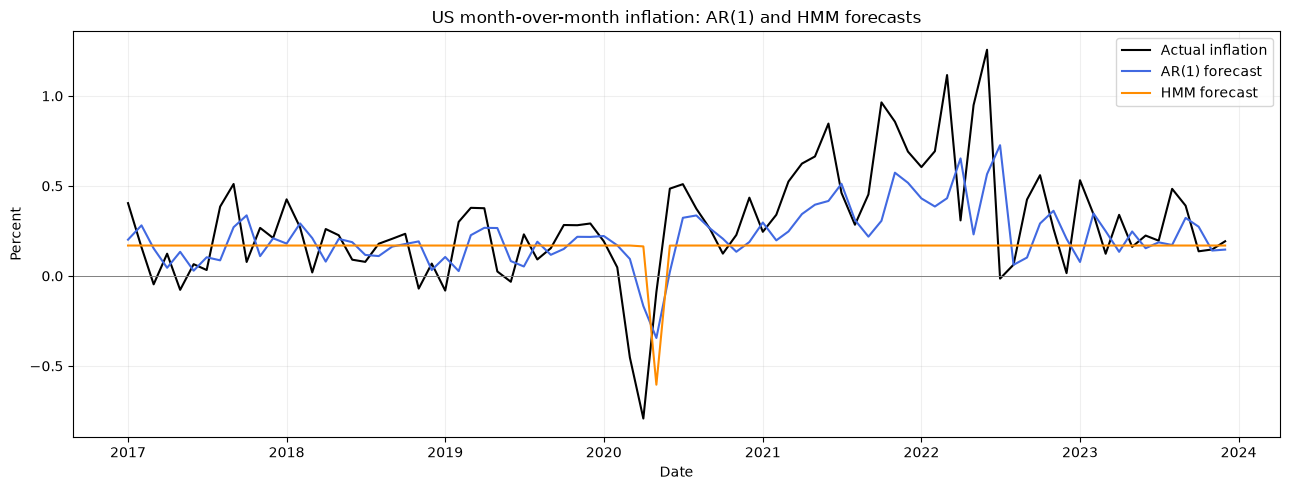

In [25]:
plt.figure(figsize=(13, 5))
plt.plot(
    forecast_test.index, forecast_test['Inflation_MoM'],
    label='Actual inflation', color='black'
)
plt.plot(
    forecast_test.index, forecast_test['Forecast_AR1'],
    label='AR(1) forecast', color='royalblue'
)
plt.plot(
    forecast_test.index, forecast_test['Forecast_HMM'],
    label='HMM forecast', color='darkorange'
)
plt.axhline(0, color='gray', linewidth=0.7)
plt.title('US month-over-month inflation: AR(1) and HMM forecasts')
plt.ylabel('Percent')
plt.xlabel('Date')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()